In [1]:
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import matplotlib.pyplot as plt

C:\Users\kanop\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "C:\Users\kanop\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
        "wmic CPU Get NumberOfCores /Format:csv".split(),
        capture_output=True,
        text=True,
    )
  File "C:\Users\kanop\anaconda3\Lib\subprocess.py", line 554, in run
    with Popen(*popenargs, **kwargs) as process:
         ~~~~~^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\kanop\anaconda3\Lib\subprocess.py", line 1039, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
    ~~~~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^

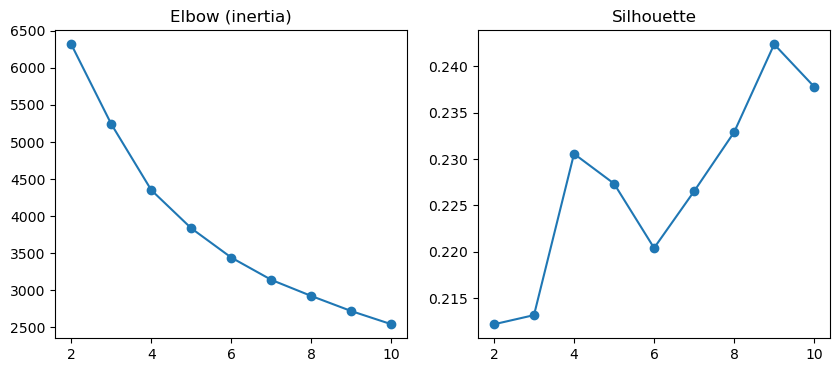

(2000, 4)


In [2]:
props = pd.read_csv("../data/processed/props_clean.csv")
sold = props[props["listing_status"] == "Sold"].copy()
sold["price_per_sqft"] = sold["sale_price"] / sold["floor_area_sqft"]
sold["is_office"] = (sold["unit_category"] == "Office").astype(int)

feat = sold.groupby("client_ref").agg(
    n_purchase=("listing_id","count"),
    avg_price=("sale_price","mean"),
    avg_price_per_sqft=("price_per_sqft","mean"),
    pct_office=("is_office","mean"),
)
X = StandardScaler().fit_transform(feat)
ks, inertia, sil = range(2,11),[],[]
for k in ks:
    km = KMeans(n_clusters=k, n_init=10, random_state=42).fit(X)
    inertia.append(km.inertia_)
    sil.append(silhouette_score(X, km.labels_))

fig, ax = plt.subplots(1,2,figsize=(10,4))
ax[0].plot(ks, inertia, marker="o"); ax[0].set_title("Elbow (inertia)")
ax[1].plot(ks, sil, marker="o"); ax[1].set_title("Silhouette")
plt.show()
print(feat.shape)

In [3]:
# fitting K-means with K=4 & profit each cluster
km = KMeans(n_clusters=4, n_init=10, random_state=42).fit(X)
feat["cluster"] = km.labels_

print(feat["cluster"].value_counts().sort_index())
print(feat.groupby("cluster").mean().round(2))

cluster
0    621
1    694
2     50
3    635
Name: count, dtype: int64
         n_purchase  avg_price  avg_price_per_sqft  pct_office
cluster                                                       
0              3.53  373097.95              309.85        0.36
1              3.66  292548.58              289.67        0.10
2              7.32  330551.39              301.20        0.13
3              3.47  382566.61              309.46        0.00


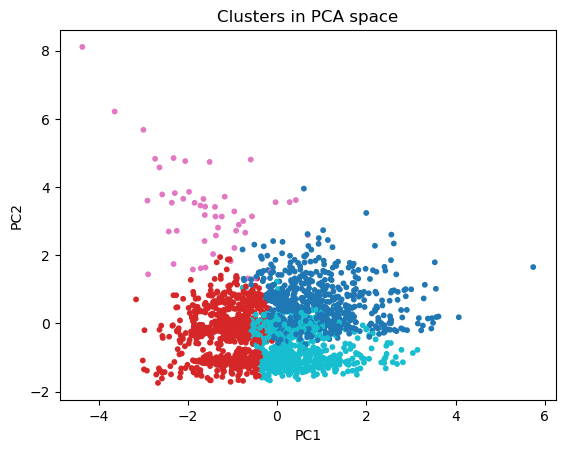

segment
Budget Buyers                 694
Residential Premium Buyers    635
Mixed-use Buyers              621
Portfolio Investors            50
Name: count, dtype: int64


In [4]:
# 2D pca scatter clusters and after that save the segment label to every client
from sklearn.decomposition import PCA

pcs = PCA(n_components=2, random_state=42).fit_transform(X)
plt.scatter(pcs[:,0], pcs[:,1], c=feat["cluster"], cmap="tab10",s=10)
plt.title("Clusters in PCA space"); plt.xlabel("PC1"); plt.ylabel("PC2")
plt.show()

names = {0:"Mixed-use Buyers", 1:"Budget Buyers",2:"Portfolio Investors",3:"Residential Premium Buyers"}
feat["segment"] = feat["cluster"].map(names)
feat.reset_index().to_csv("../data/processed/client_segments.csv", index=False)
print(feat["segment"].value_counts())

In [5]:
# attaching the client information to the segment and then compare with segment profiles
clients = pd.read_csv("../data/processed/clients_clean.csv")
seg = pd.read_csv("../data/processed/client_segments.csv")
prof = clients.merge(seg, left_on="client_id", right_on="client_ref")
print(len(prof))

for col in ["client_type","loan_applied","acquisition_purpose","referral_channel"]:
    print(pd.crosstab(prof["segment"], prof[col], normalize="index").round(2), "\n")
print(prof.groupby("segment")["satisfaction_score"].mean().round(2))


2000
client_type                 Company  Individual
segment                                        
Budget Buyers                  0.04        0.96
Mixed-use Buyers               0.06        0.94
Portfolio Investors            0.02        0.98
Residential Premium Buyers     0.06        0.94 

loan_applied                  No   Yes
segment                               
Budget Buyers               0.63  0.37
Mixed-use Buyers            0.63  0.37
Portfolio Investors         0.68  0.32
Residential Premium Buyers  0.63  0.37 

acquisition_purpose         Home  Investment
segment                                     
Budget Buyers               0.71        0.29
Mixed-use Buyers            0.68        0.32
Portfolio Investors         0.66        0.34
Residential Premium Buyers  0.69        0.31 

referral_channel            Agency  Client  Website
segment                                            
Budget Buyers                 0.39    0.10     0.51
Mixed-use Buyers              0.35    0.1

In [6]:
# building the segment summary (like size, revenue share, averages) after that saving.
sold_seg = sold.merge(seg[["client_ref","segment"]], on = "client_ref")
summary = sold_seg.groupby("segment").agg(
    clients=("client_ref","nunique"),
    total_sales=("sale_price","sum"),
    avg_price=("sale_price","mean"),
    pct_office=("is_office","mean"),
)
summary["avg_purchase"] = sold_seg.groupby("segment").size()/summary["clients"]
summary["revenue_share"] = summary["total_sales"]/summary["total_sales"].sum()
print(summary.round(2))
summary.to_csv("../data/processed/segment_summary.csv")

                            clients   total_sales  avg_price  pct_office  \
segment                                                                    
Budget Buyers                   694  7.444265e+08  293196.74        0.10   
Mixed-use Buyers                621  8.149629e+08  371281.49        0.36   
Portfolio Investors              50  1.201714e+08  328337.12        0.13   
Residential Premium Buyers      635  8.411902e+08  381492.15        0.00   

                            avg_purchase  revenue_share  
segment                                                  
Budget Buyers                       3.66           0.30  
Mixed-use Buyers                    3.53           0.32  
Portfolio Investors                 7.32           0.05  
Residential Premium Buyers          3.47           0.33  
